# v0 – Base model: predict t90 directly

The first model version of the Stoßlüften surrogate. It applies the seminar template (unit 3, *Modelltraining mit Scikit-Learn*) to our dataset with as few changes as possible, so that later versions have a baseline to beat.

![Flow of v0_base](images/v0_base_flow.png)

**How to read it:** grey is the data, blue the training on the training cases, orange the prediction and the scores on the test cases. The two vertical arrows are what training hands over to the prediction: the fitted scaling and categories, and the fitted models.

| | v0 |
|---|---|
| Data | `results/dataset_550/dataset_550.csv`, rows with `status = ok` |
| Target | `t90_s`: time until 90 % of the room air is replaced |
| Inputs | the 10 setup values of a simulation: layout, window positions, modes, angles, hinges, wind speed |
| Models | mean value (reference), LinearRegression, Ridge, DecisionTree |
| Known limit | a regressor needs a number as target, so cases that do not reach 90 % within 600 s (empty `t90_s`) are left out |

The column meanings are in [results/README.md](../results/README.md).

## 1) Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

VERSION = "v0_base"
RANDOM_STATE = 42

DATA_PATH = Path("../results/dataset_550/dataset_550.csv")
RESULTS_DIR = Path("results")
print("Data file:", DATA_PATH, "| found:", DATA_PATH.exists())

Data file: ../results/dataset_550/dataset_550.csv | found: True


## 2) Load the data

Only rows with `status = ok` are used. The 9 `failed` rows have no results (a numerical fault in the simulation; they will be rerun).

`case_id` becomes the index, so every prediction can be traced back to its simulation.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df[df["status"] == "ok"].set_index("case_id")

TARGET_COL = "t90_s"
# Only values that are fixed before a simulation starts (same choice as in unit 2)
FEATURE_COLS = [
    "layout",
    "window1_x_m",
    "window1_mode",
    "window1_angle_deg",
    "window1_hinge",
    "window2_x_m",
    "window2_mode",
    "window2_angle_deg",
    "window2_hinge",
    "wind_speed_ms",
]

print("Simulations:", len(df))
print("Missing input values:", int(df[FEATURE_COLS].isna().sum().sum()))

t90_reached = df[TARGET_COL].notna()
display(pd.crosstab(
    df["layout"],
    t90_reached.map({True: "t90 reached", False: "t90 > 600 s"}),
    margins=True,
    margins_name="total",
))

Simulations: 541
Missing input values: 0


t90_s,t90 > 600 s,t90 reached,total
layout,,,
adjacent_walls,22,228,250
opposite_walls,20,230,250
same_wall,34,7,41
total,76,465,541


Most same-wall cases (both windows in the wind-facing wall) do not reach 90 % within the 10 simulated minutes, so they have no `t90_s`.

## 3) Train/test split – the same in every version

- 80 % of the simulations for training, 20 % for testing, `random_state = 42`.
- Stratified by layout **and** by whether t90 is reached. Same-wall cases are rare (41) and mostly do not reach t90; without this, the test set got only 5 of them.
- The split is made on all `ok` cases, before anything is left out. **Every later version uses exactly this code**, so all versions are tested on the same simulations. Changing it makes the versions incomparable.
- The separate test run `test-v1` (30 new simulations) will be the final test once it has run. Until then, this split is used to compare the versions.

In [3]:
strata = df["layout"] + " / " + np.where(t90_reached, "reached", "not reached")

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=strata,
)

print("Training simulations:", len(train_df))
print("Test simulations:    ", len(test_df))
display(pd.crosstab(test_df["layout"], test_df[TARGET_COL].notna().map({True: "t90 reached", False: "t90 > 600 s"})))

Training simulations: 432
Test simulations:     109


t90_s,t90 > 600 s,t90 reached
layout,,
adjacent_walls,5,46
opposite_walls,4,46
same_wall,7,1


### Only in v0: keep the cases with a t90 value

A regressor needs a number as its target. v0 therefore drops the cases without `t90_s`, in training and in the test. The model never sees the slowest cases, and almost all same-wall cases disappear.

In [4]:
train = train_df[train_df[TARGET_COL].notna()]
test = test_df[test_df[TARGET_COL].notna()]

X_train, y_train = train[FEATURE_COLS], train[TARGET_COL]
X_test, y_test = test[FEATURE_COLS], test[TARGET_COL]

kept = pd.DataFrame({
    "train": train["layout"].value_counts(),
    "train dropped": train_df["layout"].value_counts() - train["layout"].value_counts(),
    "test": test["layout"].value_counts(),
    "test dropped": test_df["layout"].value_counts() - test["layout"].value_counts(),
})
display(kept)
print("Training:", X_train.shape, "| Test:", X_test.shape)

,train,train dropped,test,test dropped
layout,,,,
adjacent_walls,182,17,46,5
opposite_walls,184,16,46,4
same_wall,6,27,1,7


Training: (372, 10) | Test: (93, 10)


## 4) Preprocessing

As in units 2 and 3: numeric inputs are standardised, categorical inputs are one-hot encoded. There is no imputer, because the inputs have no missing values (checked in section 2).

`build_preprocessor()` returns a new, unfitted preprocessor on every call, so each model pipeline is fitted on its own.

In [5]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [col for col in FEATURE_COLS if col not in num_cols]


def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


print("Numeric inputs:    ", num_cols)
print("Categorical inputs:", cat_cols)

Numeric inputs:     ['window1_x_m', 'window1_angle_deg', 'window2_x_m', 'window2_angle_deg', 'wind_speed_ms']
Categorical inputs: ['layout', 'window1_mode', 'window1_hinge', 'window2_mode', 'window2_hinge']


## 5) Models as pipelines

Each model is the last step of a pipeline whose first step is the preprocessor (template, section 5). The parameters are those of the template.

The **mean value** (`DummyRegressor`) always predicts the average t90 of the training cases. It is the reference: a useful model has to beat it clearly.

In [6]:
models = {
    "Mean value (reference)": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "DecisionTree": DecisionTreeRegressor(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE),
}

pipelines = {}
predictions = pd.DataFrame(index=X_test.index)
for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocess", build_preprocessor()),
        ("model", model),
    ])
    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline
    predictions[name] = pipeline.predict(X_test)

display(pd.concat([y_test.rename("t90 simulated"), predictions], axis=1).head().round(0))

,t90 simulated,Mean value (reference),LinearRegression,Ridge,DecisionTree
case_id,,,,,
train-a-v2_092,187.0,226.0,222.0,225.0,189.0
train-a-v2_136,173.0,226.0,151.0,160.0,234.0
train-v1_074,64.0,226.0,33.0,39.0,92.0
train-v1_095,458.0,226.0,373.0,371.0,381.0
train-v1_080,50.0,226.0,112.0,120.0,92.0


## 6) Evaluation on the test cases

- **MAE**: mean absolute error in seconds. Smaller is better.
- **RMSE**: root mean squared error in seconds. It weighs large errors more than the MAE.
- **R²**: share of the spread of t90 that the model explains. 1 is perfect, 0 is no better than the mean value.

One split is not yet a reliable comparison. Cross-validation will come in a later version.

In [7]:
def scores(y_true, y_pred):
    return {
        "MAE [s]": mean_absolute_error(y_true, y_pred),
        "RMSE [s]": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
        "lowest prediction [s]": np.min(y_pred),
    }


results = pd.DataFrame({name: scores(y_test, predictions[name]) for name in predictions}).T
display(results.round(3))

,MAE [s],RMSE [s],R²,lowest prediction [s]
Mean value (reference),114.969,142.066,-0.005,225.591
LinearRegression,53.050,70.382,0.753,-24.833
Ridge,53.450,73.060,0.734,-12.601
DecisionTree,42.081,62.447,0.806,92.036


A t90 below 0 s is physically impossible. The *lowest prediction* column shows whether a model produces such values.

The error per layout shows where a model is weak. The `n` column is the number of test cases behind each value.

In [8]:
abs_error = predictions.sub(y_test, axis=0).abs()
per_layout = abs_error.groupby(test["layout"]).mean()
per_layout.insert(0, "n", test["layout"].value_counts())
display(per_layout.round(0).rename_axis("MAE [s] by layout"))

,n,Mean value (reference),LinearRegression,Ridge,DecisionTree
MAE [s] by layout,,,,,
adjacent_walls,46,111.0,40.0,38.0,38.0
opposite_walls,46,119.0,65.0,65.0,41.0
same_wall,1,130.0,95.0,211.0,263.0


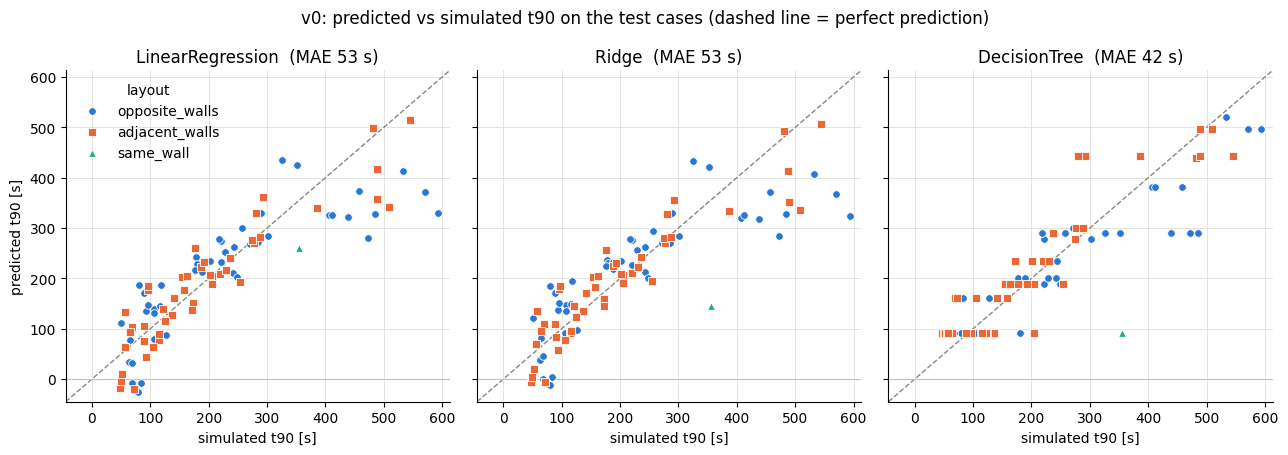

In [9]:
# Colour and marker per layout, the same in every version
LAYOUT_STYLE = {
    "opposite_walls": ("#2a78d6", "o"),
    "adjacent_walls": ("#eb6834", "s"),
    "same_wall": ("#1baf7a", "^"),
}
plot_models = ["LinearRegression", "Ridge", "DecisionTree"]

low = min(0, predictions[plot_models].min().min()) - 20
high = max(y_test.max(), predictions[plot_models].max().max()) + 20

fig, axes = plt.subplots(1, len(plot_models), figsize=(13, 4.6), sharex=True, sharey=True)
for ax, name in zip(axes, plot_models):
    ax.plot([low, high], [low, high], color="#898781", linewidth=1, linestyle="--", zorder=1)
    ax.axhline(0, color="#c3c2b7", linewidth=0.8, zorder=1)
    for layout, (color, marker) in LAYOUT_STYLE.items():
        in_layout = test["layout"] == layout
        ax.scatter(
            y_test[in_layout], predictions.loc[in_layout, name],
            s=30, color=color, marker=marker, edgecolor="white", linewidth=0.6,
            label=layout, zorder=2,
        )
    ax.set_title(f"{name}  (MAE {results.loc[name, 'MAE [s]']:.0f} s)")
    ax.set_xlabel("simulated t90 [s]")
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.grid(color="#e1e0d9", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("predicted t90 [s]")
axes[0].legend(title="layout", frameon=False, loc="upper left")
fig.suptitle("v0: predicted vs simulated t90 on the test cases (dashed line = perfect prediction)")
fig.tight_layout()
plt.show()

## 7) What the models learned

The linear model's coefficients refer to the standardised and one-hot encoded inputs (template, section 6). The decision tree's *feature importance* is the share of the error reduction that each input achieves in the tree. Neither is proof of a physical cause: inputs can be correlated, and a model only approximates the real relationship.

In [10]:
feature_names = pipelines["LinearRegression"].named_steps["preprocess"].get_feature_names_out()

coefficients = pd.Series(pipelines["LinearRegression"].named_steps["model"].coef_, index=feature_names)
importances = pd.Series(pipelines["DecisionTree"].named_steps["model"].feature_importances_, index=feature_names)

display(coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(8).round(1).to_frame("LinearRegression coefficient [s]"))
display(importances.sort_values(ascending=False).head(8).round(3).to_frame("DecisionTree importance"))

,LinearRegression coefficient [s]
layout_same_wall,147.9
layout_adjacent_walls,-77.5
wind_speed_ms,-72.7
layout_opposite_walls,-70.4
window2_hinge_none,44.4
window2_mode_turn,-44.4
window2_mode_tilt,44.4
window1_mode_tilt,36.9


,DecisionTree importance
window2_angle_deg,0.413
wind_speed_ms,0.304
window1_hinge_none,0.248
window2_x_m,0.015
window1_angle_deg,0.014
window1_x_m,0.007
window2_hinge_none,0.000
window2_hinge_left,0.000


## 8) Save the results

Every version writes two files to `ml/results/`, so the versions can be compared in [ml/README.md](README.md) and case by case in later notebooks:

- `<version>.csv`: the scores, one row per model. All scores are for t90 on the same test cases: those of the shared split that have a t90 value.
- `<version>_test_predictions.csv`: the predicted t90 of every model for each of these test cases.

In [11]:
RESULTS_DIR.mkdir(exist_ok=True)
summary = results.drop(columns="lowest prediction [s]").reset_index(names="model")
summary.insert(0, "version", VERSION)
summary["target"] = TARGET_COL
summary["n_train"] = len(X_train)
summary["n_test"] = len(X_test)
summary.to_csv(RESULTS_DIR / f"{VERSION}.csv", index=False, float_format="%.3f")

test_predictions = pd.concat([y_test.rename("t90 simulated"), predictions], axis=1)
test_predictions.to_csv(RESULTS_DIR / f"{VERSION}_test_predictions.csv", index_label="case_id", float_format="%.1f")
display(summary.round(3))

,version,model,MAE [s],RMSE [s],R²,target,n_train,n_test
0,v0_base,Mean value (reference),114.969,142.066,-0.005,t90_s,372,93
1,v0_base,LinearRegression,53.050,70.382,0.753,t90_s,372,93
2,v0_base,Ridge,53.450,73.060,0.734,t90_s,372,93
3,v0_base,DecisionTree,42.081,62.447,0.806,t90_s,372,93


## 9) Findings and next version

**Result** (dataset_550, shared split, 93 test cases with t90): the decision tree is best (MAE 42 s, R² 0.81), ahead of the linear models (MAE 53 s, R² 0.75) and far ahead of the mean value (MAE 115 s). The 10 setup values clearly determine t90.

**Weak points of v0:**

1. **The slowest cases are missing.** 76 of the 541 simulations have no t90 and are left out, among them 34 of the 41 same-wall cases. The models have seen only 6 same-wall cases and the test has only 1, so v0 says nothing reliable about same-wall windows. In use, v0 would also predict a t90 below 600 s for a setup that never reaches 90 %.
2. **The linear models predict negative t90** for fast cases (down to −25 s) and underestimate slow cases above about 400 s. The relation is not linear: on different walls, τ scales almost exactly with 1 / wind speed (exponent −0.95), so doubling the wind halves t90 instead of subtracting a fixed amount.
3. **The tree predicts in steps.** With depth 4 it has at most 16 different outputs, so all fast cases get about 92 s.
4. `window_hinge = none` means the same as `window_mode = tilt`, so the tilt information is encoded twice. This does not hurt the predictions, but it splits the importance between two columns.

**Next version, v1:** predict `tau_s`, which is defined for every case, also when t90 > 600 s, and compute t90 = ln(10) · τ ≈ 2.3 · τ. Train on log(τ), so that predictions stay positive and a factor of 2 counts the same for fast and slow cases. Evaluate t90 on the same test cases as here, and also check whether the 16 test cases without t90 are recognised as "t90 > 600 s".